# ECG-Based Cardiac Arrhythmia Detection Using Machine Learning
MIT-BIH Arrhythmia Database | AAMI beat classes (N, S, V, F) | patient-level split (DS1 / DS2)
Pipeline: audit -> split -> filter + beat windows -> RR and wavelet features -> grouped CV -> test -> error analysis

# 1. Problem Definition

## Problem
Cardiac arrhythmias are abnormal heart rhythms that can be
difficult to identify consistently from long ECG recordings.

## Objective
Develop a machine-learning system that classifies individual
ECG beats into selected AAMI arrhythmia classes using ECG
morphology and RR-interval features.

## Input
Two-channel ambulatory ECG recordings from the MIT-BIH
Arrhythmia Database.

## Output
Predicted AAMI beat class:
N, S, V, F

## Scope
This project focuses on beat-level classification and is
intended as an ML research/educational prototype, not a
clinical diagnostic system.

## Stakeholders
- Cardiologists
- ECG researchers
- Healthcare ML researchers
- Clinical decision-support developers


In [ ]:
!pip install wfdb imbalanced-learn xgboost -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 3.2 MB/s eta 0:00:00


In [ ]:
%%capture
from google.colab import drive
import os, wfdb
drive.mount("/content/drive")
BASE = "/content/drive/MyDrive/1College/Sem-5/AUCML"
DATA_DIR = BASE + "/mit-bih-arrhythmia-database-1.0.0"

# download from PhysioNet only if the folder is not already in Drive
if not os.path.exists(DATA_DIR):
    wfdb.dl_database("mitdb", dl_dir=DATA_DIR)

Dataset:
MIT-BIH Arrhythmia Database

Source:
PhysioNet

Recordings:
48 half-hour ECG recordings

Subjects:
47 subjects

Sampling frequency:
360 Hz

Leads:
Two-channel ECG

Primary lead:
MLII

Target:
AAMI beat class

Selected classes:
N, S, V, F

In [ ]:
#Import Required Libraries
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pywt
from collections import Counter
from scipy.signal import butter, sosfiltfilt
from scipy.stats import skew, kurtosis

SEED = 42
rng = np.random.default_rng(SEED)

# results are saved in Drive so a disconnect does not lose them
WORK_DIR = BASE + "/work"
os.makedirs(WORK_DIR, exist_ok=True)

FS = 360
PRE, POST = 90, 90                # samples kept before and after each R-peak
CLASSES = ["N", "S", "V", "F"]
LABEL_ID = {c: i for i, c in enumerate(CLASSES)}

# Records 102, 104, 107, 217 have paced beats, so most papers leave them out
PACED = ["102", "104", "107", "217"]

# The standard inter-patient split (de Chazal): DS1 trains, DS2 tests
DS1 = ["101","106","108","109","112","114","115","116","118","119","122",
       "124","201","203","205","207","208","209","215","220","223","230"]
DS2 = ["100","103","105","111","113","117","121","123","200","202","210",
       "212","213","214","219","221","222","228","231","232","233","234"]

# Map the raw beat symbols to the 5 AAMI classes
AAMI = {
    "N": "N", "L": "N", "R": "N", "e": "N", "j": "N",
    "A": "S", "a": "S", "J": "S", "S": "S",
    "V": "V", "E": "V",
    "F": "F",
    "/": "Q", "f": "Q", "Q": "Q",
}

In [ ]:
# Every record id is a .hea file name without the extension
all_records = sorted(f[:-4] for f in os.listdir(DATA_DIR) if f.endswith(".hea"))
print("records found:", len(all_records))

rows = []
for rec in all_records:
    path = os.path.join(DATA_DIR, rec)
    header = wfdb.rdheader(path)
    ann = wfdb.rdann(path, "atr")

    # count only the symbols that are real beats in our AAMI map
    counts = Counter(AAMI[s] for s in ann.symbol if s in AAMI)

    rows.append({"record": rec, "fs": header.fs, "leads": ",".join(header.sig_name),
                 "n_samples": header.sig_len, "n_beats": sum(counts.values()),
                 "N": counts["N"], "S": counts["S"], "V": counts["V"],
                 "F": counts["F"], "Q": counts["Q"]})

audit = pd.DataFrame(rows)
print(audit.head())

# Every record should be 360 Hz and 650,000 samples (30 minutes)
print(audit["fs"].value_counts())
print(audit["n_samples"].describe())

# Overall class balance, Normal dominates heavily
print(audit[["N", "S", "V", "F", "Q"]].sum())

# The MLII lead is used, so check which records lack it
print("records without MLII:", audit[~audit["leads"].str.contains("MLII")]["record"].tolist())

records found: 48
  record   fs    leads  n_samples  n_beats     N   S  V  F     Q
0    100  360  MLII,V5     650000     2273  2239  33  1  0     0
1    101  360  MLII,V1     650000     1865  1860   3  0  0     2
2    102  360    V5,V2     650000     2187    99   0  4  0  2084
3    103  360  MLII,V2     650000     2084  2082   2  0  0     0
4    104  360    V5,V2     650000     2229   163   0  2  0  2064
fs
360    48
Name: count, dtype: int64
count        48.0
mean     650000.0
std           0.0
min      650000.0
25%      650000.0
50%      650000.0
75%      650000.0
max      650000.0
Name: n_samples, dtype: float64
N    90631
S     2781
V     7236
F      803
Q     8043
dtype: int64
records without MLII: ['102', '104']


In [ ]:
# Drop the paced records so they never reach either side
audit = audit[~audit["record"].isin(PACED)].reset_index(drop=True)

train_df = audit[audit["record"].isin(DS1)].reset_index(drop=True)
test_df = audit[audit["record"].isin(DS2)].reset_index(drop=True)
print("train records:", len(train_df), " test records:", len(test_df))

# A record must never appear on both sides
print("overlap:", len(set(train_df["record"]) & set(test_df["record"])))  # must be 0

# compare class balance between the two sets
for name, df in [("DS1 train", train_df), ("DS2 test", test_df)]:
    totals = df[["N", "S", "V", "F", "Q"]].sum()
    print(name, (totals / totals.sum()).round(4).to_dict())

train_df.to_csv(WORK_DIR + "/train_records.csv", index=False)
test_df.to_csv(WORK_DIR + "/test_records.csv", index=False)

train records: 22  test records: 22
overlap: 0
DS1 train {'N': 0.899, 'S': 0.0185, 'V': 0.0742, 'F': 0.0081, 'Q': 0.0002}
DS2 test {'N': 0.8903, 'S': 0.037, 'V': 0.0648, 'F': 0.0078, 'Q': 0.0001}


In [ ]:
# band-pass 0.5-40 Hz removes baseline drift and high-frequency noise
sos = butter(3, [0.5, 40], btype="band", fs=FS, output="sos")

def load_clean_signal(rec):
    # read only the MLII lead by name, since lead order differs between records
    r = wfdb.rdrecord(os.path.join(DATA_DIR, rec), channel_names=["MLII"])
    return sosfiltfilt(sos, r.p_signal[:, 0])

def morph_features(beat):
    # wavelet coarse shape plus simple statistics describe the beat's morphology
    coeffs = pywt.wavedec(beat, "db4", level=4)
    energy = [np.sum(c ** 2) for c in coeffs[1:]]
    stats = [beat.max(), beat.min(), beat.max() - beat.min(), beat.std(),
             skew(beat), kurtosis(beat), np.argmax(beat), np.argmin(beat)]
    return np.concatenate([coeffs[0], energy, stats])

In [ ]:
def extract_record(rec):
    sig = load_clean_signal(rec)
    ann = wfdb.rdann(os.path.join(DATA_DIR, rec), "atr")

    # use every real beat for RR timing, even the ones we will not classify
    idx = [i for i, s in enumerate(ann.symbol) if s in AAMI]
    peaks = ann.sample[idx]
    labels = [AAMI[ann.symbol[i]] for i in idx]

    # RR intervals in seconds: gap before and after each beat
    rr = np.diff(peaks) / FS
    pre_rr = pd.Series(np.r_[np.nan, rr]).fillna(np.median(rr)).values
    post_rr = pd.Series(np.r_[rr, np.nan]).fillna(np.median(rr)).values

    # average of the last 10 intervals, plus the record's overall average
    local_avg = pd.Series(pre_rr).rolling(10, min_periods=1).mean().values
    rec_avg = rr.mean()

    beats, feats, ys = [], [], []
    for k, (p, lab) in enumerate(zip(peaks, labels)):
        if lab not in LABEL_ID:                 # drop the rare Q class
            continue
        if p - PRE < 0 or p + POST > len(sig):  # skip beats cut off at the edges
            continue

        beat = sig[p - PRE:p + POST]
        beat = (beat - beat.mean()) / (beat.std() + 1e-8)   # z-score each beat

        rr_feats = [pre_rr[k], post_rr[k], local_avg[k],
                    pre_rr[k] / rec_avg, post_rr[k] / rec_avg,
                    pre_rr[k] / local_avg[k]]

        beats.append(beat)
        feats.append(np.concatenate([rr_feats, morph_features(beat)]))
        ys.append(LABEL_ID[lab])

    return np.array(beats), np.array(feats), np.array(ys), np.array([rec] * len(ys))

train: (51002, 180) (51002, 35)
test:  (49691, 180) (49691, 35)
train class counts: {'N': np.int64(45856), 'S': np.int64(944), 'V': np.int64(3788), 'F': np.int64(414)}
bad values: 0 0


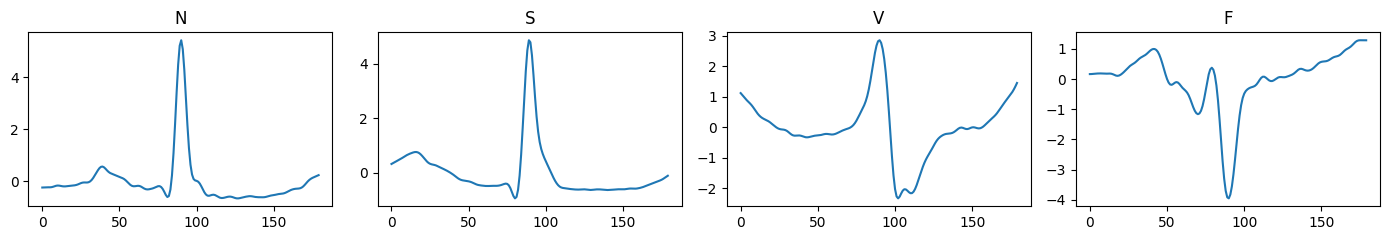

In [ ]:
def build_set(record_list):
    B, F, Y, G = [], [], [], []
    for rec in record_list:
        b, f, y, g = extract_record(rec)
        B.append(b); F.append(f); Y.append(y); G.append(g)
    return np.vstack(B), np.vstack(F), np.concatenate(Y), np.concatenate(G)

# the test set is built here only so it exists; we do not tune on it
Xb_train, Xf_train, y_train, g_train = build_set(train_df["record"])
Xb_test, Xf_test, y_test, g_test = build_set(test_df["record"])

print("train:", Xb_train.shape, Xf_train.shape)
print("test: ", Xb_test.shape, Xf_test.shape)
print("train class counts:", dict(zip(CLASSES, np.bincount(y_train))))
print("bad values:", (~np.isfinite(Xf_train)).sum(), (~np.isfinite(Xf_test)).sum())

# sanity check: plot one training beat from each class
fig, axes = plt.subplots(1, 4, figsize=(14, 2.5))
for c, ax in enumerate(axes):
    ax.plot(Xb_train[y_train == c][0])
    ax.set_title(CLASSES[c])
plt.tight_layout(); plt.show()

# save everything so we can reload without redoing the filtering
np.savez_compressed(WORK_DIR + "/beats.npz",
    Xb_train=Xb_train, Xf_train=Xf_train, y_train=y_train, g_train=g_train,
    Xb_test=Xb_test, Xf_test=Xf_test, y_test=y_test, g_test=g_test)

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE
from scipy.stats import loguniform, randint, uniform

# folds are split by record, so one patient never sits in both train and validation
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

def make_pipe(model):
    # every step here is fitted inside the training fold only
    return Pipeline([
        ("scale", StandardScaler()),
        ("select", SelectKBest(f_classif)),
        # shrink the huge Normal class, then SMOTE the rare ones up to 4000
        ("under", RandomUnderSampler(sampling_strategy={0: 8000}, random_state=SEED)),
        ("smote", SMOTE(sampling_strategy={1: 4000, 2: 4000, 3: 4000}, random_state=SEED)),
        ("model", model),
    ])

# each entry: pipeline, hyperparameter space, number of random trials
configs = {
    "LogReg": (
        make_pipe(LogisticRegression(max_iter=500)),
        {"select__k": [15, 25, 35], "model__C": loguniform(1e-2, 1e2)}, 6),
    "RandomForest": (
        make_pipe(RandomForestClassifier(random_state=SEED, n_jobs=1)),
        {"select__k": [15, 25, 35], "model__n_estimators": randint(100, 300),
         "model__max_depth": [10, 20, None], "model__min_samples_leaf": randint(1, 5)}, 8),
    "XGBoost": (
        make_pipe(XGBClassifier(tree_method="hist", n_jobs=1, random_state=SEED)),
        {"select__k": [15, 25, 35], "model__n_estimators": randint(150, 400),
         "model__max_depth": randint(3, 8), "model__learning_rate": loguniform(0.03, 0.3),
         "model__subsample": uniform(0.7, 0.3)}, 10),
    "SVM": (
        make_pipe(SVC(kernel="rbf")),
        {"select__k": [15, 25, 35], "model__C": loguniform(0.5, 20),
         "model__gamma": loguniform(1e-3, 1e-1)}, 4),
}

In [ ]:
import time, joblib

best_models, cv_results = {}, []

for name, (pipe, space, n_iter) in configs.items():
    t0 = time.time()
    search = RandomizedSearchCV(
        pipe, space, n_iter=n_iter, cv=cv,
        scoring="f1_macro",          # macro-F1 so the rare classes count equally
        refit=True,                  # refit on the full DS1 pool
        n_jobs=-1, random_state=SEED)

    # groups tells the CV which record each beat belongs to
    search.fit(Xf_train, y_train, groups=g_train)

    best_models[name] = search.best_estimator_
    cv_results.append({"model": name, "cv_macro_f1": round(search.best_score_, 4),
                       "best_params": search.best_params_,
                       "minutes": round((time.time() - t0) / 60, 1)})
    print(name, "done:", round(search.best_score_, 4))

cv_table = pd.DataFrame(cv_results).sort_values("cv_macro_f1", ascending=False)
print(cv_table.to_string(index=False))

# save the fitted models and the CV table
joblib.dump(best_models, WORK_DIR + "/best_models.joblib")
cv_table.to_csv(WORK_DIR + "/cv_results.csv", index=False)

LogReg done: 0.4348
RandomForest done: 0.4764
XGBoost done: 0.496
SVM done: 0.4759
       model  cv_macro_f1                                                                                                                                              best_params  minutes
     XGBoost       0.4960 {'model__learning_rate': 0.06049716507542575, 'model__max_depth': 7, 'model__n_estimators': 279, 'model__subsample': 0.905269907953647, 'select__k': 35}      5.1
RandomForest       0.4764                                                      {'model__max_depth': 10, 'model__min_samples_leaf': 4, 'model__n_estimators': 203, 'select__k': 35}     13.2
         SVM       0.4759                                                                 {'model__C': 0.8889607461211928, 'model__gamma': 0.0013066739238053278, 'select__k': 15}      2.6
      LogReg       0.4348                                                                                                       {'model__C': 0.05416754583247458, 'se

       model  accuracy  macro_precision  macro_recall  macro_f1  macro_auc
RandomForest    0.9062           0.6049        0.7724    0.6431     0.9587
         SVM    0.7512           0.5807        0.6589    0.5715     0.8673
     XGBoost    0.8785           0.5579        0.6589    0.5707     0.9378
      LogReg    0.7806           0.5569        0.6281    0.5608     0.8614
class              N       S       V       F
model                                       
LogReg        0.8678  0.4685  0.9059  0.0011
RandomForest  0.9477  0.5423  0.9272  0.1554
SVM           0.8464  0.5080  0.9139  0.0178
XGBoost       0.9311  0.3005  0.9504  0.1007
class              N       S       V       F
model                                       
LogReg        0.7770  0.8312  0.8938  0.0103
RandomForest  0.9148  0.6924  0.9565  0.5258
SVM           0.7451  0.8008  0.8705  0.2191
XGBoost       0.8985  0.3310  0.9680  0.4381


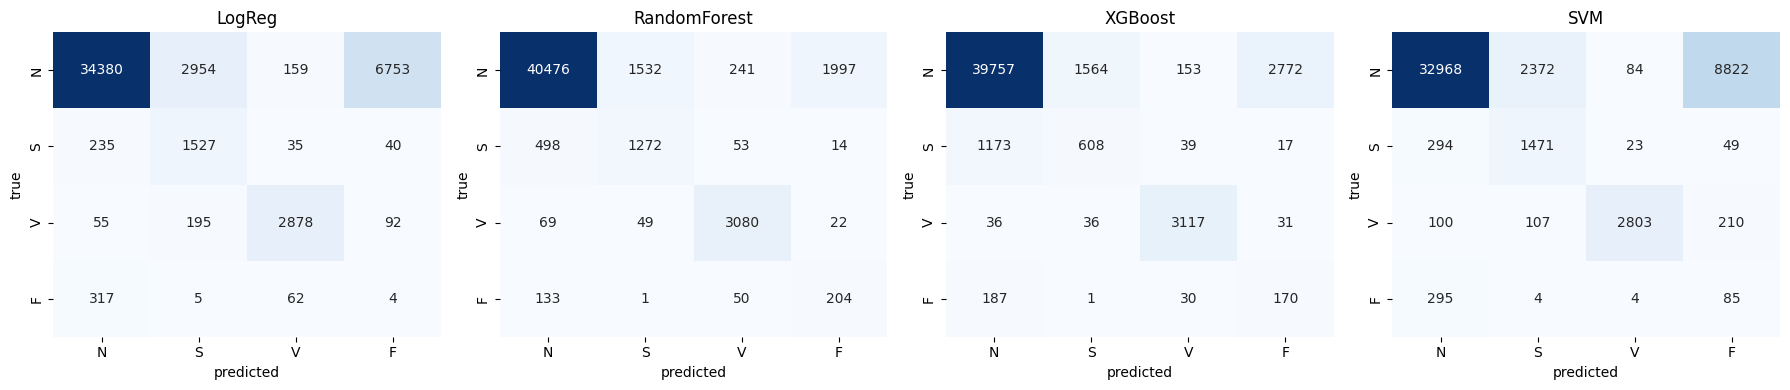

In [ ]:
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, roc_auc_score)

summary, per_class, cms = [], [], {}

for name, model in best_models.items():
    pred = model.predict(Xf_test)

    # SVM has no probabilities, so fall back to its decision scores for AUC
    scores = model.predict_proba(Xf_test) if hasattr(model, "predict_proba") \
             else model.decision_function(Xf_test)

    p, r, f, _ = precision_recall_fscore_support(y_test, pred, labels=[0, 1, 2, 3], zero_division=0)
    aucs = [roc_auc_score(y_test == c, scores[:, c]) for c in range(4)]  # one-vs-rest

    summary.append({"model": name, "accuracy": accuracy_score(y_test, pred),
                    "macro_precision": p.mean(), "macro_recall": r.mean(),
                    "macro_f1": f.mean(), "macro_auc": np.mean(aucs)})
    for c, cls in enumerate(CLASSES):
        per_class.append({"model": name, "class": cls,
                          "precision": p[c], "recall": r[c], "f1": f[c]})
    cms[name] = confusion_matrix(y_test, pred, labels=[0, 1, 2, 3])

summary_df = pd.DataFrame(summary).sort_values("macro_f1", ascending=False).round(4)
per_class_df = pd.DataFrame(per_class).round(4)

print(summary_df.to_string(index=False))
print(per_class_df.pivot(index="model", columns="class", values="f1")[CLASSES])
print(per_class_df.pivot(index="model", columns="class", values="recall")[CLASSES])

# confusion matrices side by side, one per model
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, cm) in zip(axes, cms.items()):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=CLASSES, yticklabels=CLASSES)
    ax.set_title(name); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); plt.show()

summary_df.to_csv(WORK_DIR + "/test_summary.csv", index=False)
per_class_df.to_csv(WORK_DIR + "/test_per_class.csv", index=False)

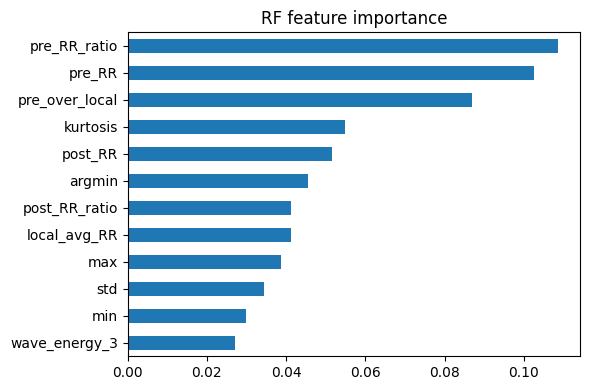

record  beats  S_true  S_found  F_true  F_found  N_as_F  N_as_S
   233   3077       7        4      11        2    1499       0
   214   2259       0        0       1        0     174       3
   210   2648      22        3      10        0     129     241
   234   2753      50        2       0        0      88       1
   202   2136      55       43       1        0      50      84
   117   1534       1        1       0        0      25       0
   105   2567       0        0       0        0      22       0
   213   3250      28        0     362      202       9       0
   121   1863       1        1       0        0       1       0
   103   2084       2        1       0        0       0       3


In [ ]:
best = best_models["RandomForest"]
rf = best.named_steps["model"]

# name every feature so the importance plot is readable
names = (["pre_RR", "post_RR", "local_avg_RR", "pre_RR_ratio", "post_RR_ratio", "pre_over_local"]
         + [f"wave_approx_{i}" for i in range(17)]
         + [f"wave_energy_{i}" for i in range(4)]
         + ["max", "min", "ptp", "std", "skew", "kurtosis", "argmax", "argmin"])

# keep only the features the selector actually kept
kept = np.array(names)[best.named_steps["select"].get_support()]
imp = pd.Series(rf.feature_importances_, index=kept).sort_values(ascending=False)
imp.head(12).iloc[::-1].plot(kind="barh", figsize=(6, 4), title="RF feature importance")
plt.tight_layout(); plt.show()

# which test records produce the most S and F errors
pred = best.predict(Xf_test)
err = pd.DataFrame({"record": g_test, "true": y_test, "pred": pred})
rows = []
for rec, d in err.groupby("record"):
    rows.append({"record": rec, "beats": len(d),
                 "S_true": (d.true == 1).sum(), "S_found": ((d.true == 1) & (d.pred == 1)).sum(),
                 "F_true": (d.true == 3).sum(), "F_found": ((d.true == 3) & (d.pred == 3)).sum(),
                 "N_as_F": ((d.true == 0) & (d.pred == 3)).sum(),
                 "N_as_S": ((d.true == 0) & (d.pred == 1)).sum()})
rec_table = pd.DataFrame(rows).sort_values("N_as_F", ascending=False)
print(rec_table.head(10).to_string(index=False))

In [ ]:
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import f1_score

models = dict(best_models)
models["Majority baseline"] = DummyClassifier(strategy="most_frequent")

rows = []
for name, model in models.items():
    scores = cross_val_score(clone(model), Xf_train, y_train, groups=g_train,
                             cv=cv, scoring="f1_macro", n_jobs=-1)
    if name == "Majority baseline":
        pred_t = clone(model).fit(Xf_train, y_train).predict(Xf_test)
    else:
        pred_t = model.predict(Xf_test)
    rows.append({"model": name, "cv_mean": scores.mean(), "cv_std": scores.std(),
                 "test_macro_f1": f1_score(y_test, pred_t, average="macro")})

cv_stats = pd.DataFrame(rows).round(4)
print(cv_stats.to_string(index=False))
cv_stats.to_csv(WORK_DIR + "/cv_mean_std.csv", index=False)

            model  cv_mean  cv_std  test_macro_f1
           LogReg   0.4348  0.1225         0.5608
     RandomForest   0.4764  0.0847         0.6431
          XGBoost   0.4960  0.1324         0.5707
              SVM   0.4759  0.1613         0.5715
Majority baseline   0.2521  0.0292         0.2355


what record 233 contains: {'N': np.int64(2229), 'S': np.int64(7), 'V': np.int64(830), 'F': np.int64(11)}
N beats wrongly called F: 1499
mean RR before/after, wrong beats: [0.591 0.523]
mean RR before/after, correct beats: [0.85  0.809]


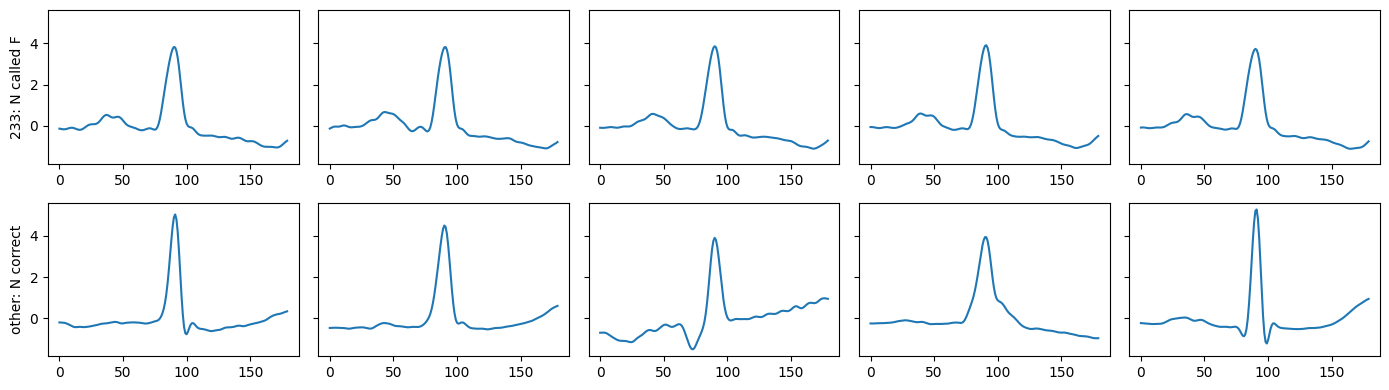

In [ ]:
# Normal beats from record 233 that the model called Fusion
bad = np.where((g_test == "233") & (y_test == 0) & (pred == 3))[0]
# Normal beats from other records that the model got right, for comparison
good = np.where((g_test != "233") & (y_test == 0) & (pred == 0))[0]

print("what record 233 contains:", dict(zip(CLASSES, np.bincount(y_test[g_test == "233"], minlength=4))))
print("N beats wrongly called F:", len(bad))

# columns 0 and 1 of the features are the RR gaps before and after the beat
print("mean RR before/after, wrong beats:", Xf_test[bad, :2].mean(axis=0).round(3))
print("mean RR before/after, correct beats:", Xf_test[good, :2].mean(axis=0).round(3))

# plot five beats of each kind
fig, axes = plt.subplots(2, 5, figsize=(14, 4), sharey=True)
for i in range(5):
    axes[0, i].plot(Xb_test[rng.choice(bad)])
    axes[1, i].plot(Xb_test[rng.choice(good)])
axes[0, 0].set_ylabel("233: N called F")
axes[1, 0].set_ylabel("other: N correct")
plt.tight_layout(); plt.show()

pre_over_local    0.0816
pre_RR_ratio      0.0773
pre_RR            0.0399
std               0.0198
post_RR           0.0195
local_avg_RR      0.0105
wave_approx_7     0.0097
argmin            0.0088
ptp               0.0077
min               0.0057
dtype: float64


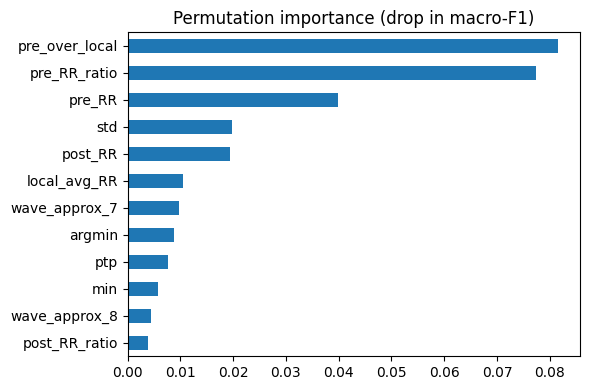

In [ ]:
from sklearn.inspection import permutation_importance

# use a random sample of the test beats to keep it quick
idx = rng.choice(len(Xf_test), size=8000, replace=False)

result = permutation_importance(best, Xf_test[idx], y_test[idx], scoring="f1_macro",
                                n_repeats=5, random_state=SEED, n_jobs=-1)

# drop in macro-F1 when each feature is shuffled; bigger drop = more important
perm = pd.Series(result.importances_mean, index=names).sort_values(ascending=False)
print(perm.head(10).round(4))

perm.head(12).iloc[::-1].plot(kind="barh", figsize=(6, 4),
                              title="Permutation importance (drop in macro-F1)")
plt.tight_layout(); plt.show()

record 200 - predicted class counts:
pred
N    1707
V     800
S      92
F       1
beat-level accuracy: 0.9692


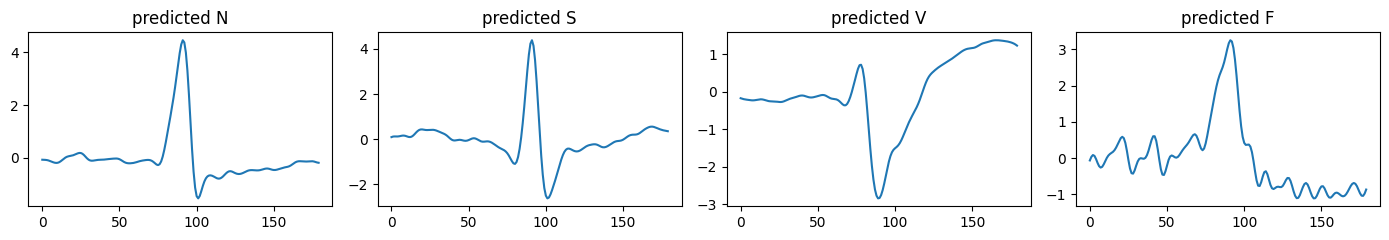

In [ ]:
def predict_record(rec, model=best_models["RandomForest"]):
    # run the same preprocessing as training, then predict every beat in the record
    b, f, y, g = extract_record(rec)
    pred = model.predict(f)
    conf = model.predict_proba(f).max(axis=1)

    out = pd.DataFrame({"beat": range(len(pred)),
                        "true": [CLASSES[i] for i in y],
                        "pred": [CLASSES[i] for i in pred],
                        "confidence": conf.round(3)})
    print("record", rec, "- predicted class counts:")
    print(out["pred"].value_counts().to_string())
    print("beat-level accuracy:", round((out["true"] == out["pred"]).mean(), 4))

    # plot the first beat predicted for each class, if the record has one
    fig, axes = plt.subplots(1, 4, figsize=(14, 2.5))
    for c, ax in enumerate(axes):
        hits = np.where(pred == c)[0]
        if len(hits):
            ax.plot(b[hits[0]])
        ax.set_title(f"predicted {CLASSES[c]}")
    plt.tight_layout(); plt.show()
    return out

# try it on a test record
demo = predict_record("200")

In [ ]:
import sklearn, xgboost, imblearn

config = {
    "seed": SEED, "fs": FS, "window": [PRE, POST], "classes": CLASSES,
    "filter": "butterworth bandpass 0.5-40 Hz, order 3, zero-phase",
    "lead": "MLII", "train_records": DS1, "test_records": DS2, "excluded_paced": PACED,
    "best_params": {r["model"]: r["best_params"] for r in cv_results},
    "versions": {"sklearn": sklearn.__version__, "xgboost": xgboost.__version__,
                 "imblearn": imblearn.__version__, "wfdb": wfdb.__version__,
                 "pywt": pywt.__version__, "numpy": np.__version__},
}
with open(WORK_DIR + "/config.json", "w") as fh:
    json.dump(config, fh, indent=2, default=str)
print("saved to", WORK_DIR)

saved to /content/drive/MyDrive/1College/Sem-5/AUCML/work


            model  accuracy  balanced_acc  macro_P  macro_R  macro_F1    MCC  kappa  macro_AUC
     RandomForest    0.9062        0.7724   0.6049   0.7724    0.6431 0.6531 0.6326     0.9587
              SVM    0.7512        0.6589   0.5807   0.6589    0.5715 0.4418 0.3599     0.8673
          XGBoost    0.8785        0.6589   0.5579   0.6589    0.5707 0.5437 0.5255     0.9378
           LogReg    0.7806        0.6281   0.5569   0.6281    0.5608 0.4701 0.3979     0.8614
Majority baseline    0.8904        0.2500   0.2226   0.2500    0.2355 0.0000 0.0000     0.5000
class                   N       S       V       F
model                                            
LogReg             0.9827  0.3262  0.9183  0.0006
Majority baseline  0.8904  0.0000  0.0000  0.0000
RandomForest       0.9830  0.4457  0.8995  0.0912
SVM                0.9795  0.3720  0.9619  0.0093
XGBoost            0.9661  0.2752  0.9335  0.0569
class                   N       S       V       F
model                         

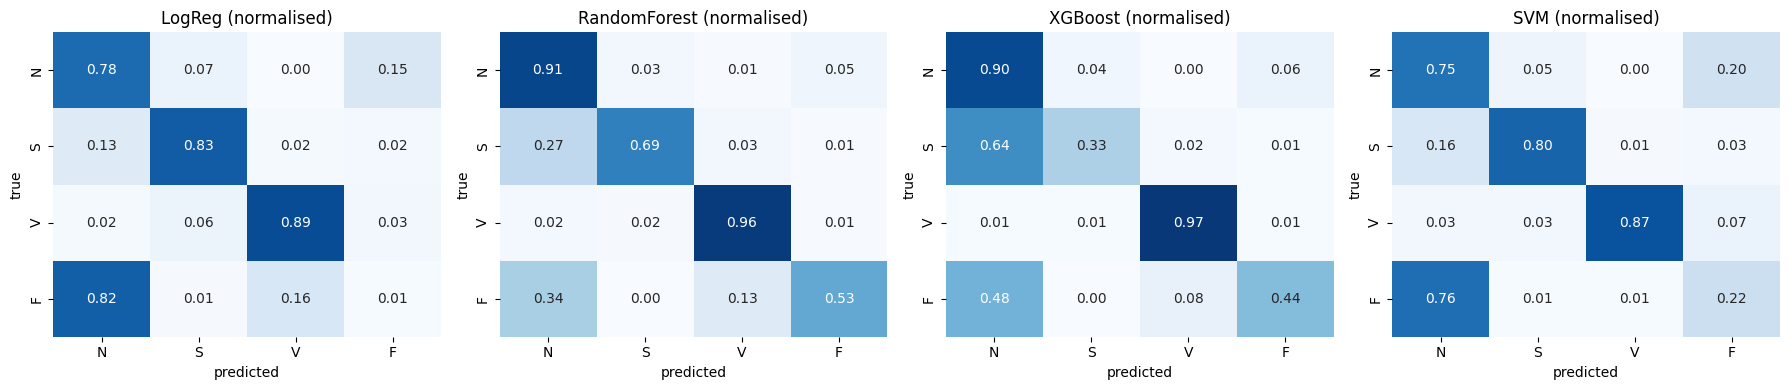

In [ ]:
from sklearn.metrics import (balanced_accuracy_score, matthews_corrcoef,
                             cohen_kappa_score, accuracy_score, roc_auc_score,
                             precision_recall_fscore_support, confusion_matrix)

all_models = dict(best_models)
all_models["Majority baseline"] = DummyClassifier(strategy="most_frequent").fit(Xf_train, y_train)

rows, pc_rows, cms_all = [], [], {}
for name, m in all_models.items():
    pred = m.predict(Xf_test)
    proba = m.predict_proba(Xf_test) if hasattr(m, "predict_proba") else m.decision_function(Xf_test)
    p, r, f, s = precision_recall_fscore_support(y_test, pred, labels=[0,1,2,3], zero_division=0)
    rows.append({"model": name,
                 "accuracy": accuracy_score(y_test, pred),
                 "balanced_acc": balanced_accuracy_score(y_test, pred),
                 "macro_P": p.mean(), "macro_R": r.mean(), "macro_F1": f.mean(),
                 "MCC": matthews_corrcoef(y_test, pred),
                 "kappa": cohen_kappa_score(y_test, pred),
                 "macro_AUC": np.mean([roc_auc_score(y_test == c, proba[:, c]) for c in range(4)])})
    for c, cls in enumerate(CLASSES):
        pc_rows.append({"model": name, "class": cls, "precision": p[c],
                        "recall": r[c], "f1": f[c], "support": s[c]})
    cms_all[name] = confusion_matrix(y_test, pred, labels=[0,1,2,3])

final_df = pd.DataFrame(rows).sort_values("macro_F1", ascending=False).round(4)
pc_df = pd.DataFrame(pc_rows).round(4)
print(final_df.to_string(index=False))
print(pc_df.pivot(index="model", columns="class", values="precision")[CLASSES])
print(pc_df.pivot(index="model", columns="class", values="recall")[CLASSES])
print(pc_df.pivot(index="model", columns="class", values="f1")[CLASSES])

# row-normalised confusion matrices: each row shows what share of a true class went where
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, name in zip(axes, best_models):
    cm = cms_all[name]
    sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".2f",
                cmap="Blues", cbar=False, vmin=0, vmax=1, ax=ax,
                xticklabels=CLASSES, yticklabels=CLASSES)
    ax.set_title(name + " (normalised)"); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); plt.show()

final_df.to_csv(WORK_DIR + "/final_metrics.csv", index=False)
pc_df.to_csv(WORK_DIR + "/final_per_class.csv", index=False)

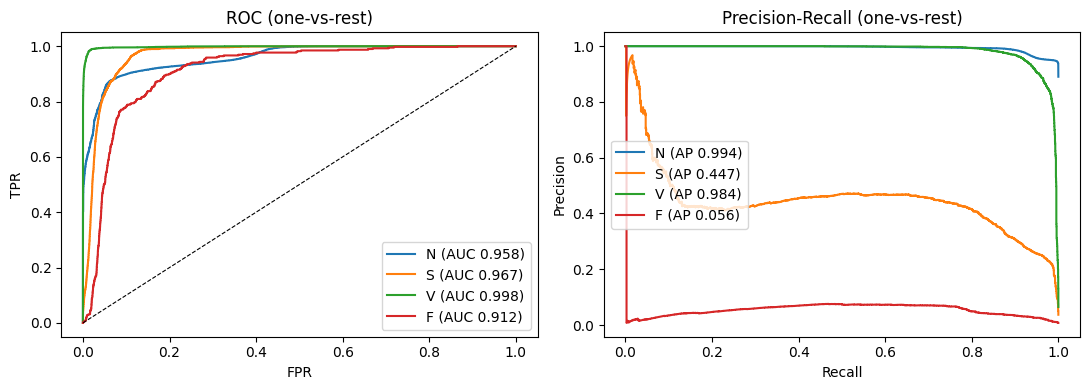

In [ ]:
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score

rfm = best_models["RandomForest"]
proba = rfm.predict_proba(Xf_test)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
for c, cls in enumerate(CLASSES):
    yt = (y_test == c)
    fpr, tpr, _ = roc_curve(yt, proba[:, c])
    pr, rc, _ = precision_recall_curve(yt, proba[:, c])
    a1.plot(fpr, tpr, label=f"{cls} (AUC {roc_auc_score(yt, proba[:, c]):.3f})")
    a2.plot(rc, pr, label=f"{cls} (AP {average_precision_score(yt, proba[:, c]):.3f})")
a1.plot([0, 1], [0, 1], "k--", lw=0.8)
a1.set(title="ROC (one-vs-rest)", xlabel="FPR", ylabel="TPR"); a1.legend()
a2.set(title="Precision-Recall (one-vs-rest)", xlabel="Recall", ylabel="Precision"); a2.legend()
plt.tight_layout(); plt.show()

In [ ]:
RR_IDX = list(range(0, 6))      # 6 RR features
MORPH_IDX = list(range(6, 35))  # wavelet + statistical features
groups = {"RR only": RR_IDX, "Morphology only": MORPH_IDX, "RR + Morphology": RR_IDX + MORPH_IDX}

rows = []
for gname, idx_ in groups.items():
    pipe = clone(best_models["RandomForest"]).set_params(select__k="all")
    pipe.fit(Xf_train[:, idx_], y_train)
    pred = pipe.predict(Xf_test[:, idx_])
    p, r, f, _ = precision_recall_fscore_support(y_test, pred, labels=[0,1,2,3], zero_division=0)
    rows.append({"features": gname, "n_feat": len(idx_), "accuracy": accuracy_score(y_test, pred),
                 "macro_F1": f.mean(), "F1_S": f[1], "F1_V": f[2], "F1_F": f[3]})
ablation = pd.DataFrame(rows).round(4)
print(ablation.to_string(index=False))
ablation.to_csv(WORK_DIR + "/ablation.csv", index=False)

       features  n_feat  accuracy  macro_F1   F1_S   F1_V   F1_F
        RR only       6    0.8215    0.4237 0.1612 0.5932 0.0259
Morphology only      29    0.8266    0.4532 0.0725 0.8166 0.0222
RR + Morphology      35    0.9062    0.6431 0.5423 0.9272 0.1554


In [ ]:
mask = g_test != "233"
rows = []
for name in best_models:
    pred = best_models[name].predict(Xf_test)
    for label, mk in [("all DS2", np.ones_like(mask)), ("excluding 233", mask)]:
        p, r, f, _ = precision_recall_fscore_support(y_test[mk], pred[mk], labels=[0,1,2,3], zero_division=0)
        rows.append({"model": name, "test set": label, "accuracy": accuracy_score(y_test[mk], pred[mk]),
                     "macro_F1": f.mean(), "F1_S": f[1], "F1_F": f[3]})
sens = pd.DataFrame(rows).round(4)
print(sens.to_string(index=False))
sens.to_csv(WORK_DIR + "/sensitivity_233.csv", index=False)

       model      test set  accuracy  macro_F1   F1_S   F1_F
      LogReg       all DS2    0.7806    0.5608 0.4685 0.0011
      LogReg excluding 233    0.7690    0.5559 0.4685 0.0003
RandomForest       all DS2    0.9062    0.6431 0.5423 0.1554
RandomForest excluding 233    0.9335    0.6960 0.5420 0.3630
     XGBoost       all DS2    0.8785    0.5707 0.3005 0.1007
     XGBoost excluding 233    0.9077    0.5975 0.2998 0.1996
         SVM       all DS2    0.7512    0.5715 0.5080 0.0178
         SVM excluding 233    0.7772    0.5761 0.5086 0.0213
